# CIFAR-100: dữ liệu, fine-tuning và phân tích lỗi

**CO5177 · Image · Học kỳ 261**  
Huỳnh Thành Đạt (2570161) · Lương Minh Duy (2570083)

Bài toán dự đoán 100 lớp ảnh, khảo sát ảnh hưởng của mức fine-tuning đến chất lượng và chi phí. Sáu đối chứng chính dùng pretrained ResNet18/Swin-T; hai đối chứng scratch cung cấp thêm ngữ cảnh.

Kết quả GPU được dùng lại từ [A1 CO5085, commit 1250e56](https://github.com/dathuynh1108/CO5085-deep-learning/tree/1250e569c6ce055391b5670e2f9a31faedb44b20). Đây là **cùng 24 lượt chạy**, không phải thí nghiệm độc lập mới. Notebook tải dữ liệu để kiểm tra và tính lại chỉ số từ predictions đã lưu; Run all không huấn luyện hoặc thuê GPU. Nguồn, SHA256 và ánh xạ code nằm trong `reports/image/reuse-manifest.json`.

## 1. Chuẩn bị

Chạy từ checkout trên máy cá nhân hoặc mở notebook trong Colab rồi chọn Run all. Trên Colab, cell sau clone repo vào `/content/CO5177-PFDAV`. Dữ liệu public khoảng 143 MB được tải về `data/`, gồm đầy đủ train/test. Phân tích chạy bằng CPU; môi trường training gốc được ghi riêng trong evidence.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
if not Path('reports/image/reuse-manifest.json').is_file():
    target = Path('/content/CO5177-PFDAV')
    if not target.exists():
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/dathuynh1108/CO5177-PFDAV.git', str(target)], check=True)
    os.chdir(target)
missing = [name for name in ['numpy', 'matplotlib', 'PIL', 'pyarrow', 'torch', 'torchvision'] if importlib.util.find_spec(name) is None]
if missing:
    packages = ['pillow' if name == 'PIL' else name for name in missing]
    subprocess.run([sys.executable, '-m', 'pip', 'install', *packages], check=True)
sys.path.insert(0, str(Path('src').resolve()))
import json, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from image.analysis import audit
from image.explore import explore, overlap_sensitivity
from image.protocol import load_protocol
root = Path.cwd()
print('Repository:', root.name)

Repository: CO5177-PFDAV


## 2. Kiểm tra bằng chứng trước khi phân tích

Mỗi prediction phải thuộc đúng checkpoint, seed, split và cấu hình. Hàm audit kiểm tra hash mọi tệp nhập, chữ ký protocol/source, lịch sử 20 epoch và checkpoint được chọn bằng validation; sau đó tính lại confusion, accuracy và macro-F1 từ đủ 10.000 prediction của từng lượt.

In [2]:
result = audit()
assert result['verified_runs'] == 24 and result['new_training_runs'] == 0
print('Đã đối chiếu:', result['verified_runs'], 'lượt; số lượt train mới:', result['new_training_runs'])
print('Nguồn:', result['source_commit'])

Đã đối chiếu: 24 lượt; số lượt train mới: 0
Nguồn: 1250e569c6ce055391b5670e2f9a31faedb44b20


## 3. Dữ liệu, phân bố và chất lượng ảnh

CIFAR-100 có 60.000 ảnh màu, 100 fine classes. Train/validation/test có 450/50/100 ảnh mỗi lớp. Các ảnh gốc đều 32×32; mức 128px trong brief là khuyến nghị. Input 96×96 giữ đúng thiết lập đã đo và giảm chi phí, nhưng không tạo thêm chi tiết.

Training gốc tải archive Toronto. Phần khám phá dùng mirror `uoft-cs/cifar100` ở revision cố định; **hash toàn bộ pixel và nhãn theo đúng thứ tự phải khớp archive gốc** trước khi phân tích. Nguồn chưa có license rõ ràng; raw data không được commit.

{'train': 45000, 'validation': 5000, 'test': 10000, 'classes': 100, 'shape': [32, 32, 3], 'ordered_pixels_match_original_training': True}


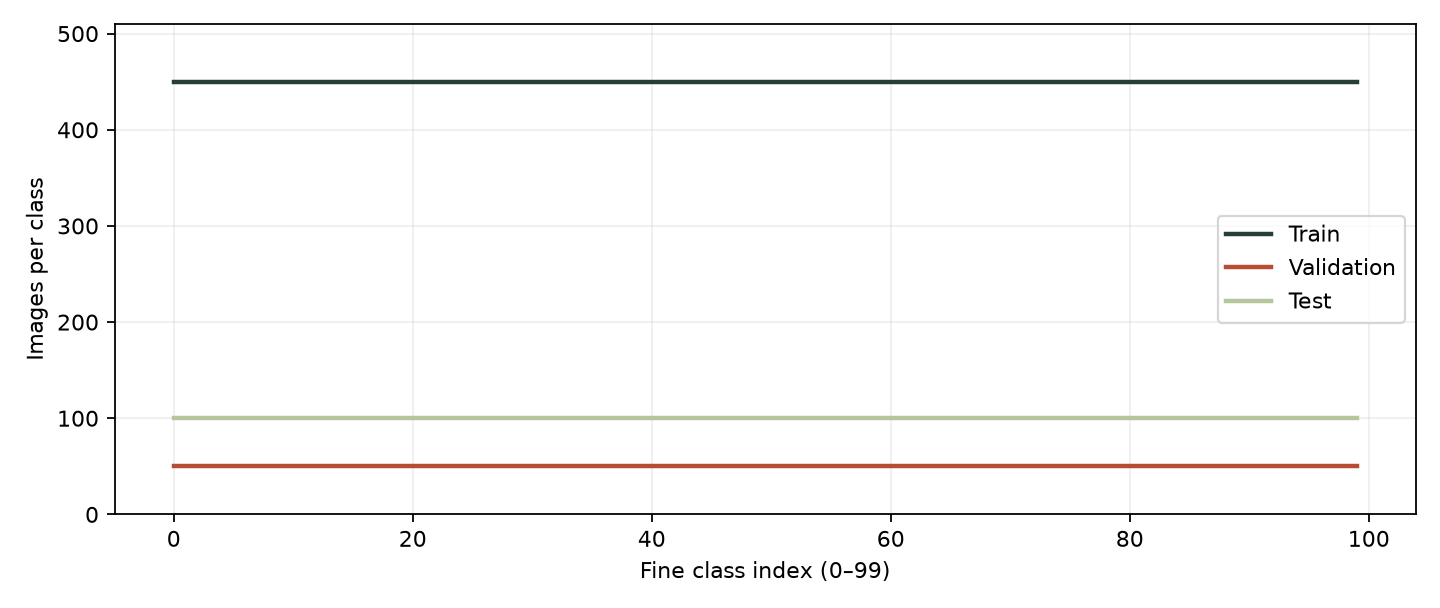

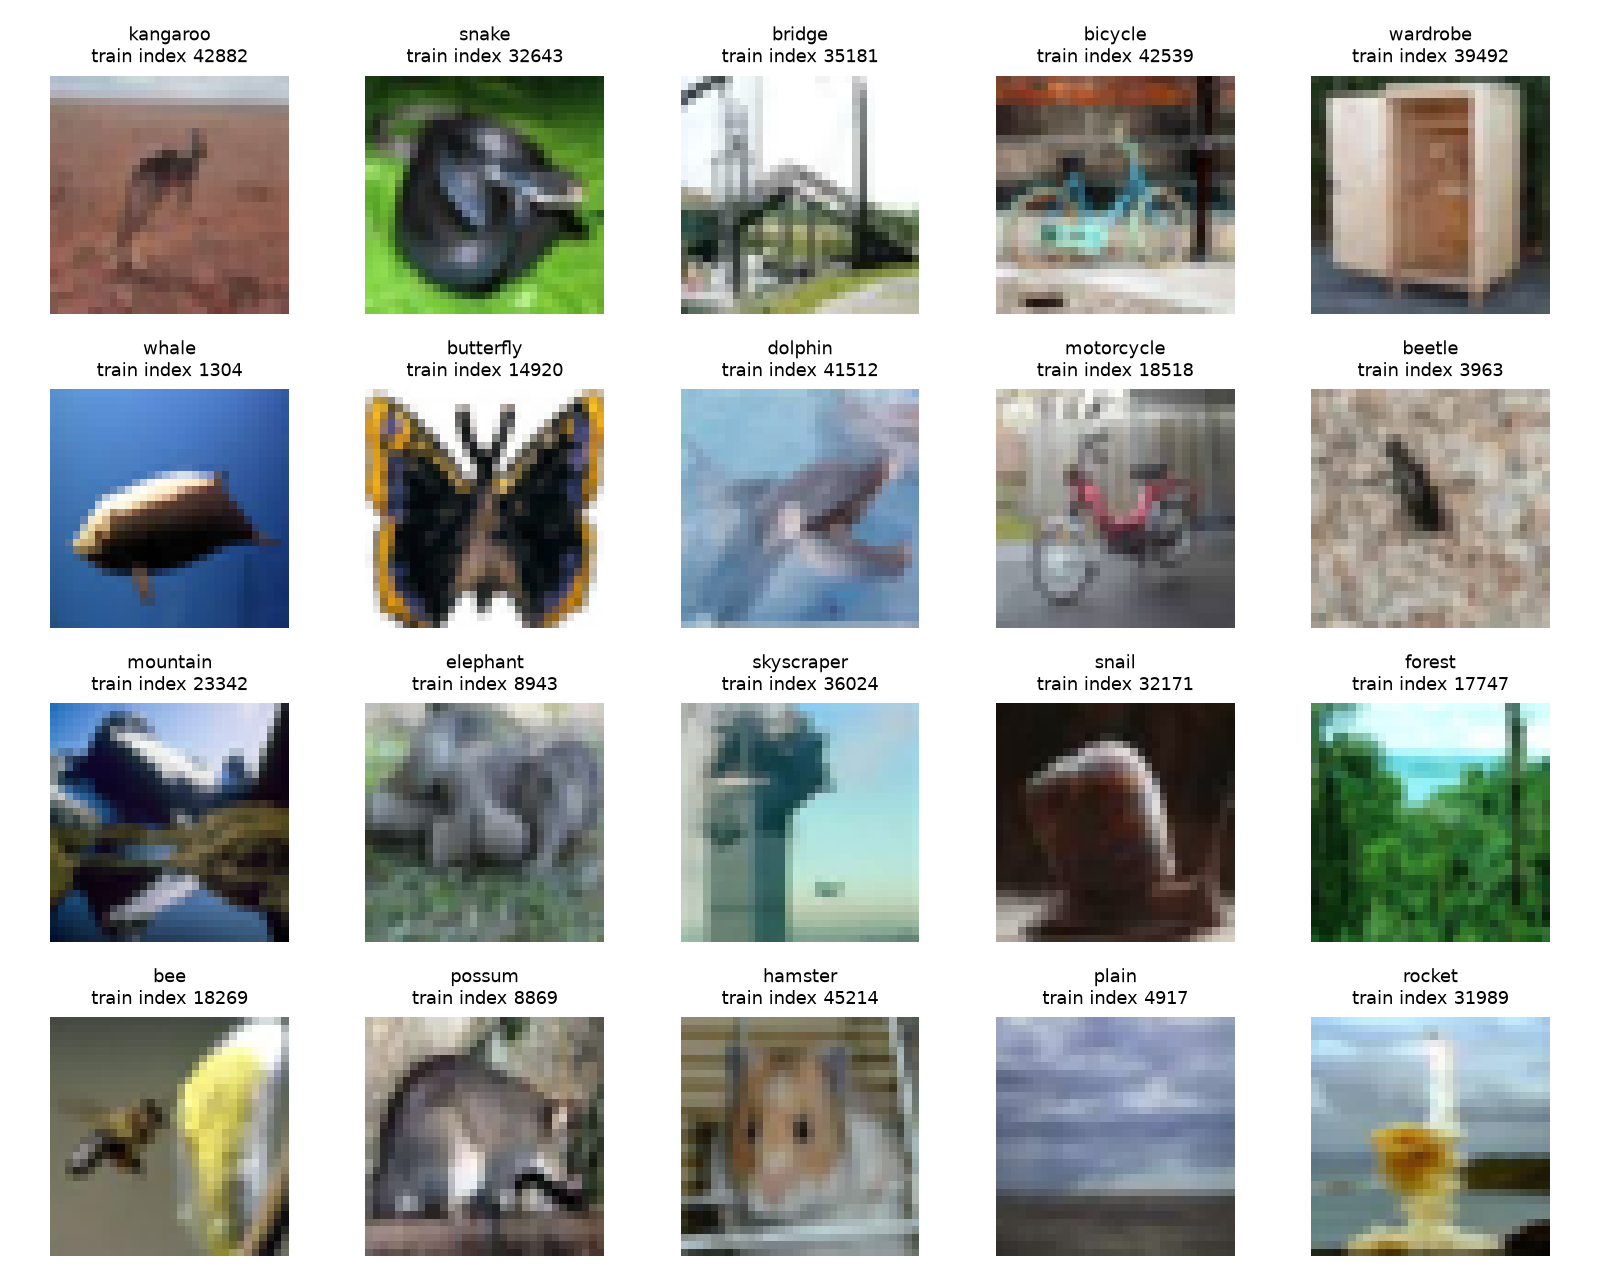

In [3]:
dataset = explore()
print({key: dataset[key] for key in ['train', 'validation', 'test', 'classes', 'shape', 'ordered_pixels_match_original_training']})
display(Image(filename='reports/image/analysis/class_counts.png'))
display(Image(filename='reports/image/analysis/training_samples.png'))

### Ảnh trùng pixel giữa các split

Tách indices riêng biệt không bảo đảm nội dung ảnh khác nhau. Kiểm tra dưới đây dùng SHA256 của toàn bộ RGB bytes cho từng ảnh, trên đầy đủ tập dữ liệu. Đây là audit bổ sung sau lượt training: không thay split đã đo hoặc chọn lại checkpoint. Near duplicates chưa được kiểm tra.

In [4]:
sensitivity = overlap_sensitivity()
print({key: dataset[key] for key in ['exact_overlap_train_val', 'exact_overlap_train_test', 'exact_overlap_val_test', 'development_duplicate_count']})
print('Ảnh test trùng train bị loại trong kiểm tra độ nhạy:', sensitivity['excluded_test_images'])
print('Số prediction giữ lại:', sensitivity['retained_test_images'])

{'exact_overlap_train_val': 2, 'exact_overlap_train_test': 10, 'exact_overlap_val_test': 0, 'development_duplicate_count': 14}
Ảnh test trùng train bị loại trong kiểm tra độ nhạy: 10
Số prediction giữ lại: 9990


## 4. Tiền xử lý và protocol

Split phân tầng seed 2026; model seed 42, 43, 44. Train dùng crop 32×32 với padding 4, flip ngang rồi resize 96×96; validation/test chỉ resize. Dùng ImageNet mean/std cố định. Head của hai kiến trúc có 100 đầu ra. Frozen backbone giữ BatchNorm/stochastic depth ở chế độ eval. Mã vòng lặp và resume nằm trong `src/image/engine.py`; các bước biến đổi nằm trong `src/image/data.py`.

Protocol được cố định trước test. Checkpoint chọn theo validation accuracy, hòa thì CE thấp hơn. Không dùng test để chọn mức fine-tuning.

In [5]:
protocol = load_protocol()
print({key: protocol[key] for key in ['epochs', 'batch_size', 'image_size', 'split_seed', 'seeds']})
for exp in protocol['experiments']:
    print(exp['id'], '| weights:', exp['weights'], '| lr:', exp['lr'])

{'epochs': 20, 'batch_size': 128, 'image_size': 96, 'split_seed': 2026, 'seeds': [42, 43, 44]}
resnet18_scratch | weights: None | lr: 0.001
resnet18_head | weights: ResNet18_Weights.IMAGENET1K_V1 | lr: 0.001
resnet18_partial | weights: ResNet18_Weights.IMAGENET1K_V1 | lr: 0.0001
resnet18_full | weights: ResNet18_Weights.IMAGENET1K_V1 | lr: 0.0001
swin_t_scratch | weights: None | lr: 0.001
swin_t_head | weights: Swin_T_Weights.IMAGENET1K_V1 | lr: 0.001
swin_t_partial | weights: Swin_T_Weights.IMAGENET1K_V1 | lr: 0.0001
swin_t_full | weights: Swin_T_Weights.IMAGENET1K_V1 | lr: 0.0001


## 5. Accuracy và chi phí

Đồ thị dùng trung bình và SD của ba seed, không chọn seed tốt nhất. Scratch là đối chứng bổ sung; yêu cầu pretrained của CO5177 được đáp ứng bởi head/partial/full. So sánh chỉ áp dụng cho ngân sách 20 epoch, không khẳng định mọi mô hình đã hội tụ.

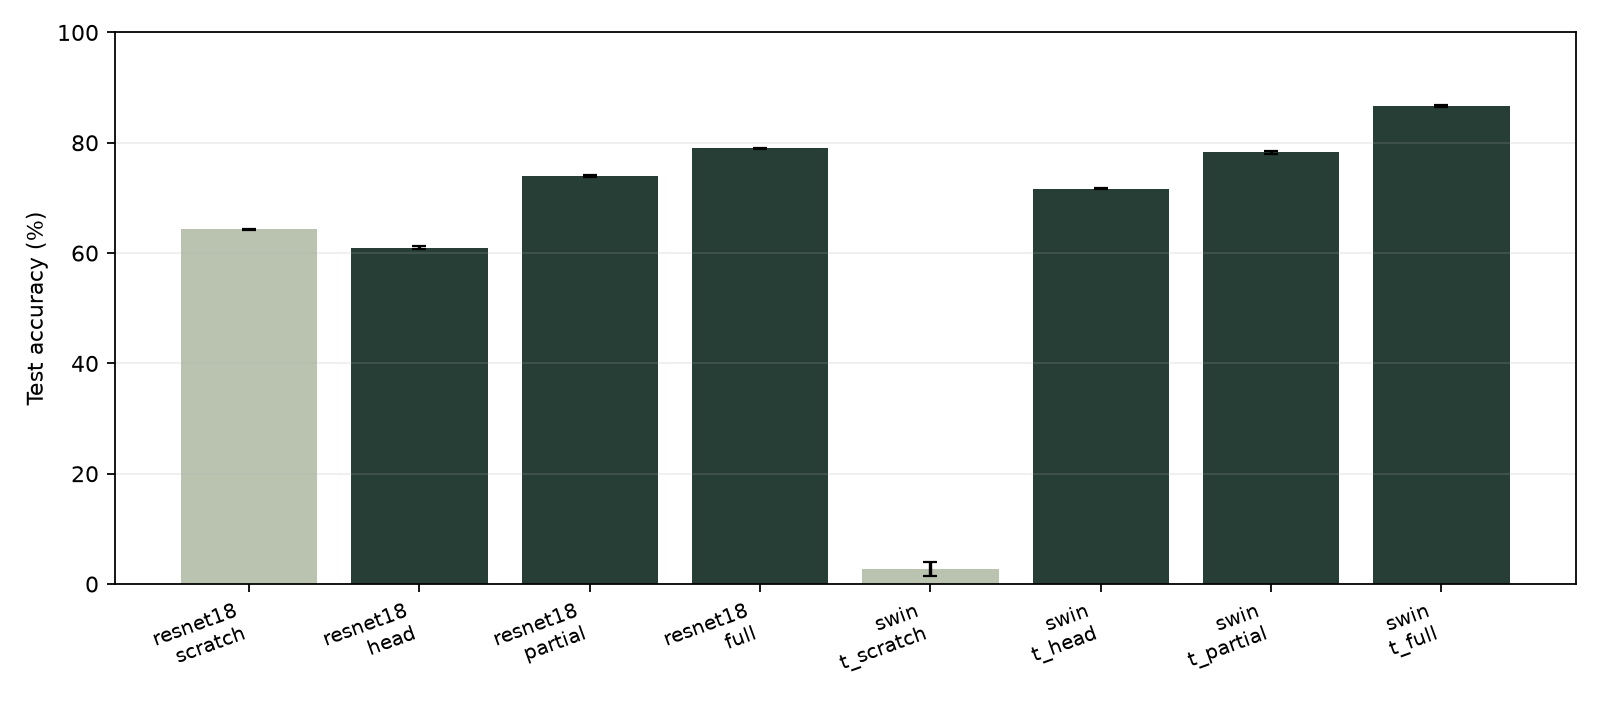

Cấu hình | Accuracy trung bình ± SD (%) | Macro-F1
resnet18_scratch     64.35 ± 0.11 | 0.6422
resnet18_head        60.95 ± 0.29 | 0.6081
resnet18_partial     73.96 ± 0.12 | 0.7396
resnet18_full        78.97 ± 0.04 | 0.7898
swin_t_scratch       2.76 ± 1.26 | 0.0093
swin_t_head          71.67 ± 0.09 | 0.7154
swin_t_partial       78.25 ± 0.22 | 0.7818
swin_t_full          86.63 ± 0.22 | 0.8663


In [6]:
groups = result['summary']
fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(groups))
ax.bar(x, [100*g['accuracy'] for g in groups], yerr=[100*g['sd'] for g in groups], capsize=3,
       color=['#b9c3b0' if g['regime']=='scratch' else '#263e35' for g in groups])
ax.set_xticks(x, [g['experiment'].replace('_','\n',1) for g in groups], rotation=20, ha='right', fontsize=9)
ax.set(ylabel='Test accuracy (%)', ylim=(0,100)); ax.grid(axis='y', alpha=.2)
fig.tight_layout(); fig.savefig('reports/image/analysis/accuracy.png', dpi=160); plt.close(fig)
display(Image(filename='reports/image/analysis/accuracy.png', width=760))
print('Cấu hình | Accuracy trung bình ± SD (%) | Macro-F1')
for g in groups:
    print(f"{g['experiment']:20s} {100*g['accuracy']:.2f} ± {100*g['sd']:.2f} | {g['macro_f1']:.4f}")

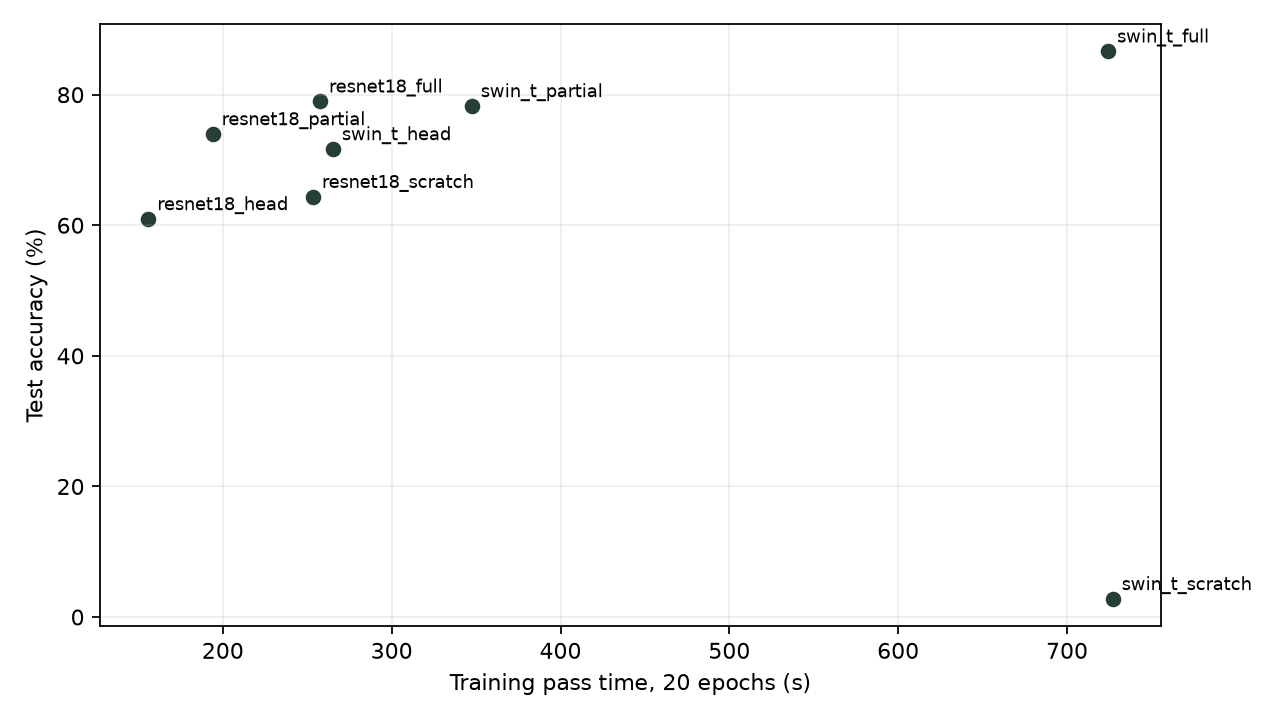

In [7]:
fig, ax = plt.subplots(figsize=(8,4.5))
for g in groups:
    rows = [r for r in result['runs'] if r['experiment']==g['experiment']]
    seconds = np.mean([r['train_seconds'] for r in rows])
    ax.scatter(seconds, g['accuracy']*100, color='#263e35')
    ax.annotate(g['experiment'], (seconds, g['accuracy']*100), xytext=(4,4), textcoords='offset points', fontsize=8)
ax.set(xlabel='Training pass time, 20 epochs (s)', ylabel='Test accuracy (%)')
ax.grid(alpha=.2); fig.tight_layout(); fig.savefig('reports/image/analysis/cost_accuracy.png',dpi=160); plt.close(fig)
display(Image(filename='reports/image/analysis/cost_accuracy.png', width=760))

### Đường cong học của các cấu hình pretrained

Các hình dưới dùng seed 42 đã định trước, với đủ 20 epoch cho head-only, partial và full fine-tuning của cả hai kiến trúc. Loss và accuracy được lấy từ lịch sử huấn luyện gốc; SHA256 của các hình nằm trong manifest.

Ở full fine-tuning, accuracy train cuối kỳ đạt khoảng 99%, trong khi validation thấp hơn. Sự chênh lệch này cho thấy giới hạn tổng quát hóa dù chất lượng test cao hơn hai chế độ còn lại. Điểm test trong bảng dùng checkpoint tốt nhất theo validation, không nhất thiết là epoch 20.

**ResNet18 · Head-only · seed 42**

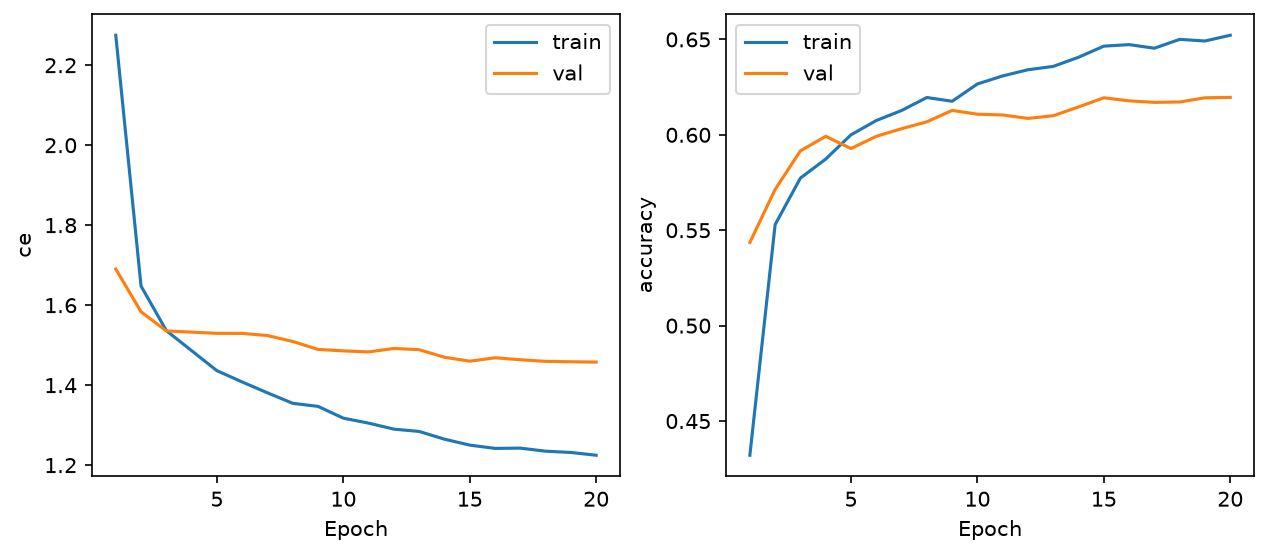

**ResNet18 · Partial · seed 42**

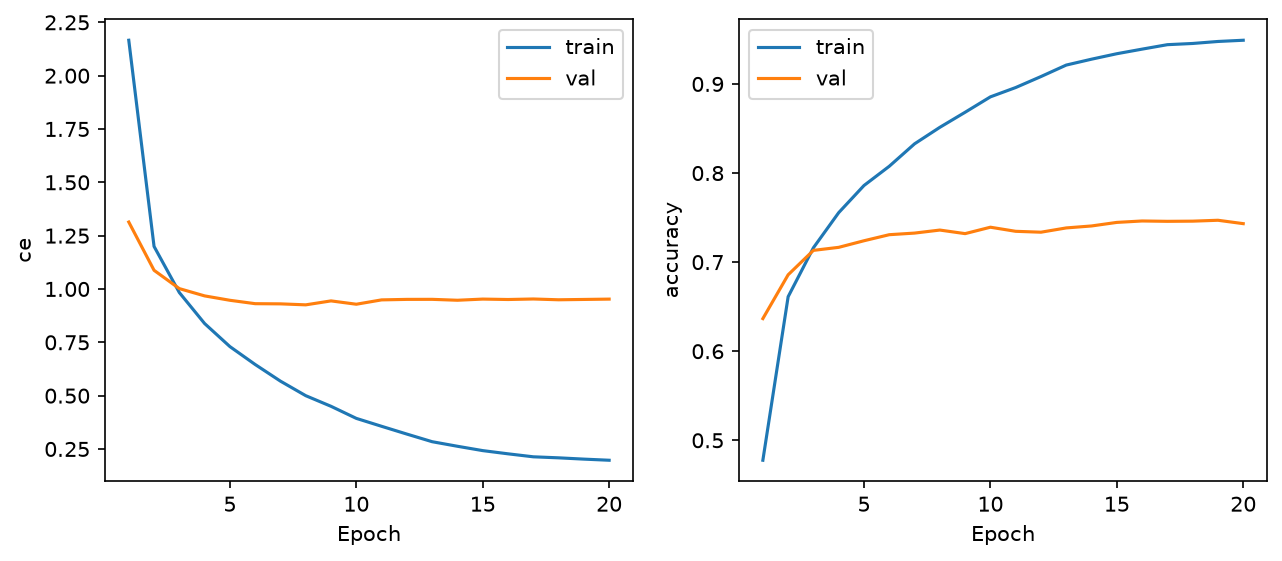

**ResNet18 · Full · seed 42**

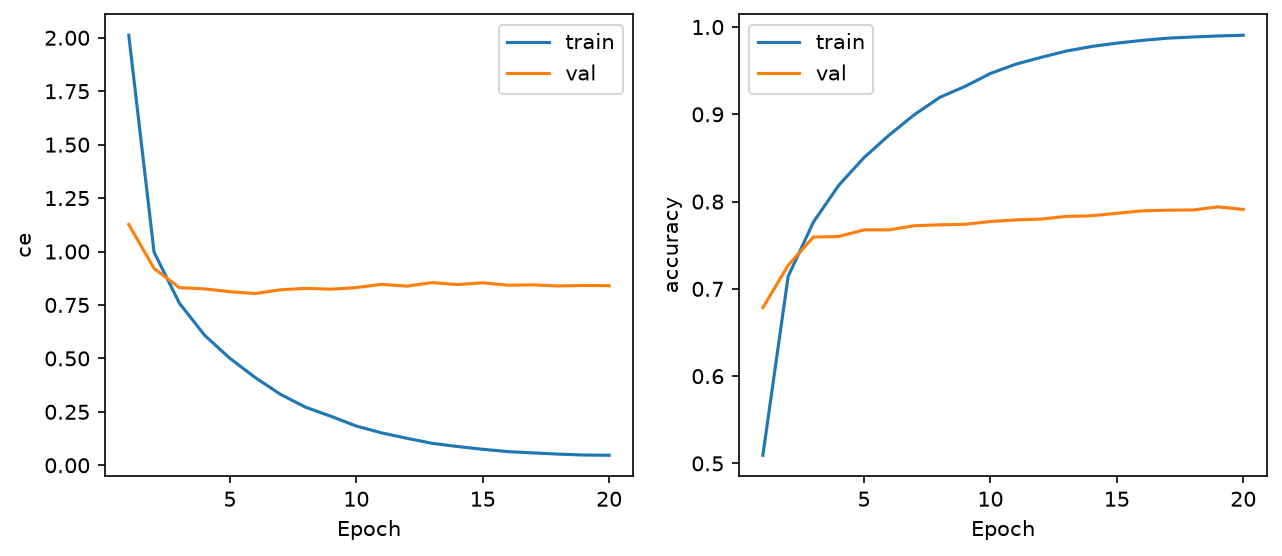

**Swin-T · Head-only · seed 42**

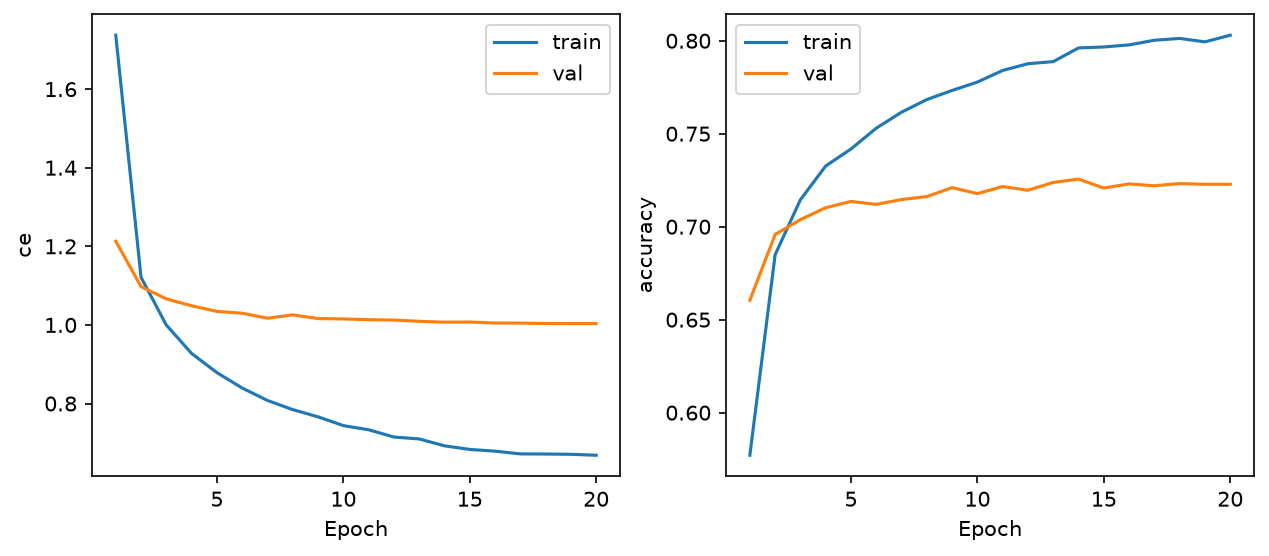

**Swin-T · Partial · seed 42**

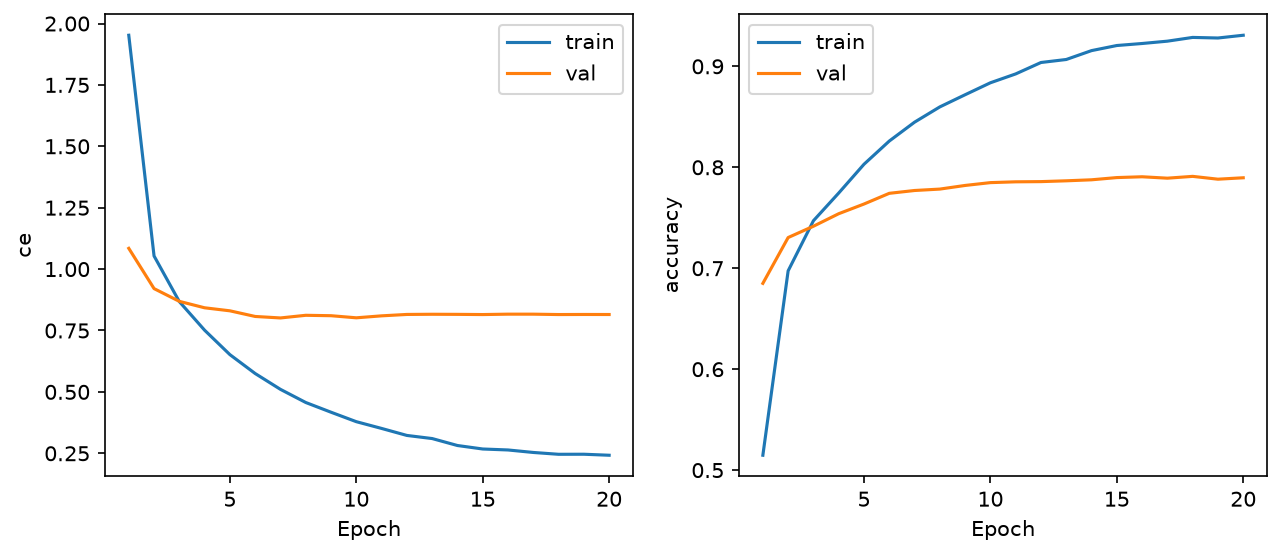

**Swin-T · Full · seed 42**

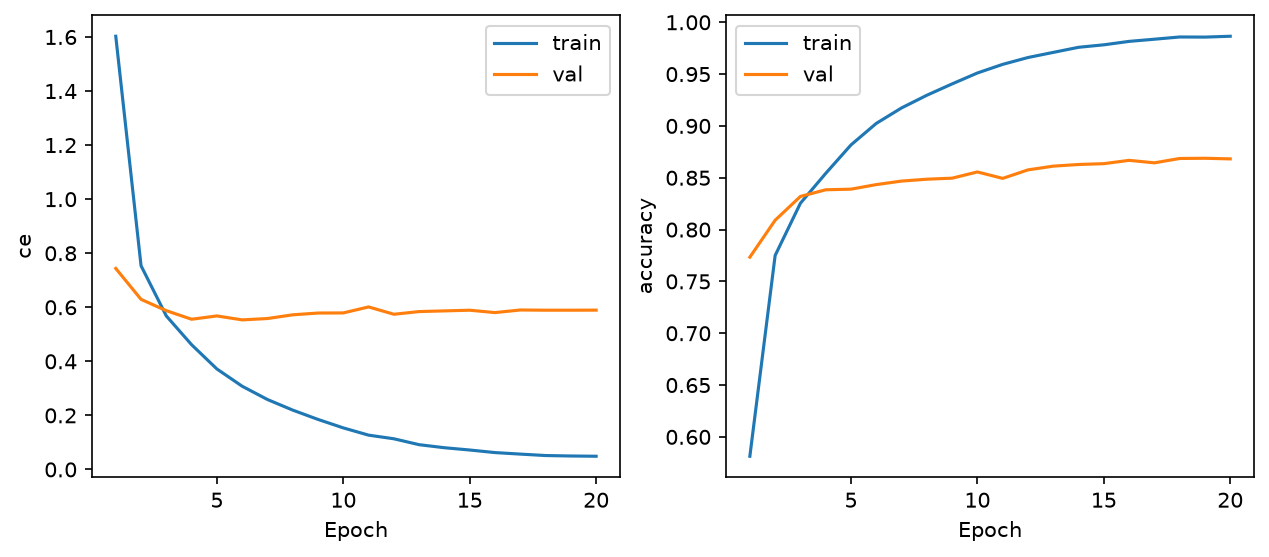

In [8]:
for architecture, name in [('resnet18', 'ResNet18'), ('swin_t', 'Swin-T')]:
    for regime, label in [('head', 'Head-only'), ('partial', 'Partial'), ('full', 'Full')]:
        display(Markdown(f'**{name} · {label} · seed 42**'))
        display(Image(filename=f'reports/image/generated/figures/{architecture}_{regime}_curves.png', width=760))

## 6. Lỗi phân loại

Dùng seed 42 cho cả hai mô hình full, theo quy tắc chọn seed nhỏ nhất đã định trước. Liệt kê các nhầm lẫn có số ảnh cao nhất; gallery hiển thị các lỗi confidence cao của cùng checkpoint. Các ví dụ này giúp giải thích khó khăn, không thay cho phép đo calibration.

resnet18_full
  oak_tree → maple_tree : 23
  maple_tree → oak_tree : 21
  boy → man : 14
  girl → woman : 14
  mouse → shrew : 14


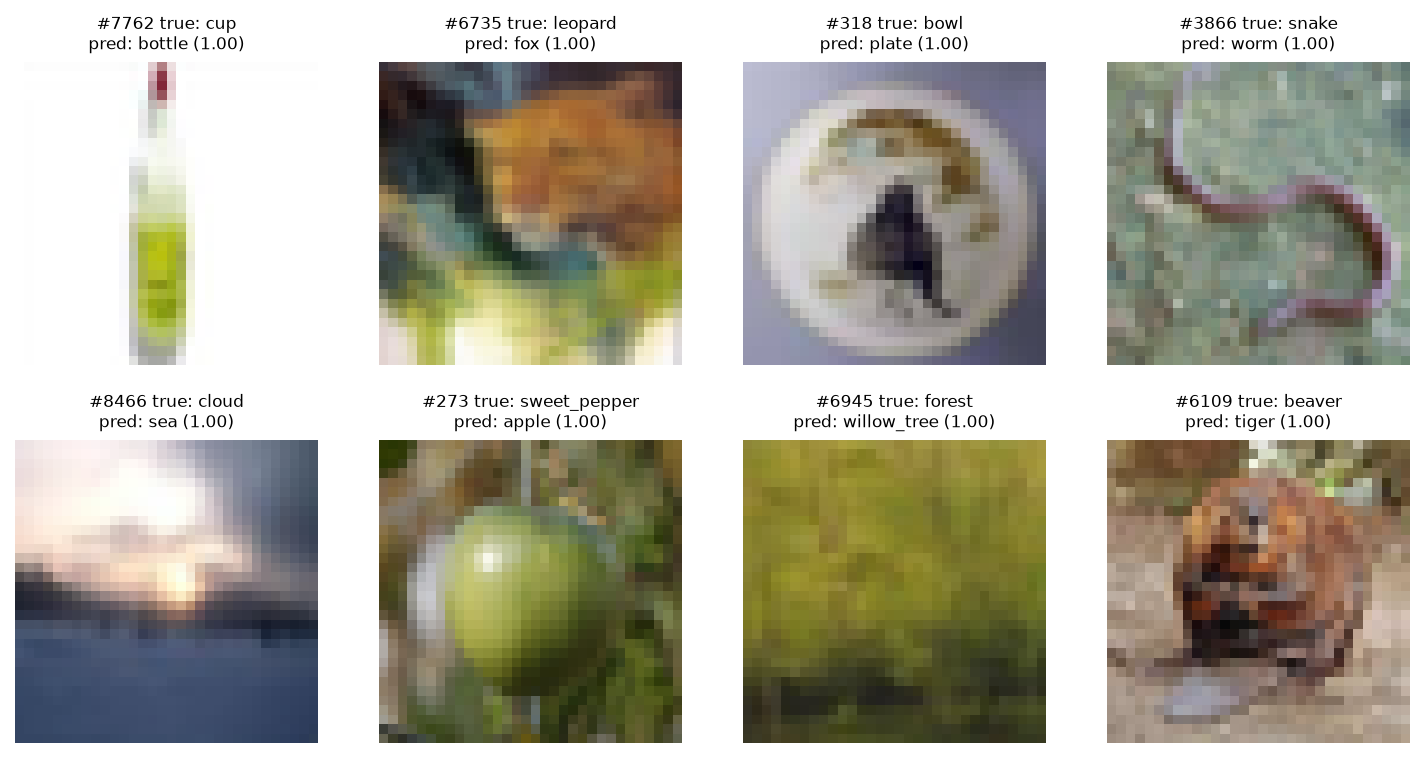

swin_t_full
  oak_tree → maple_tree : 22
  maple_tree → oak_tree : 15
  pine_tree → oak_tree : 13
  boy → man : 13
  boy → girl : 12


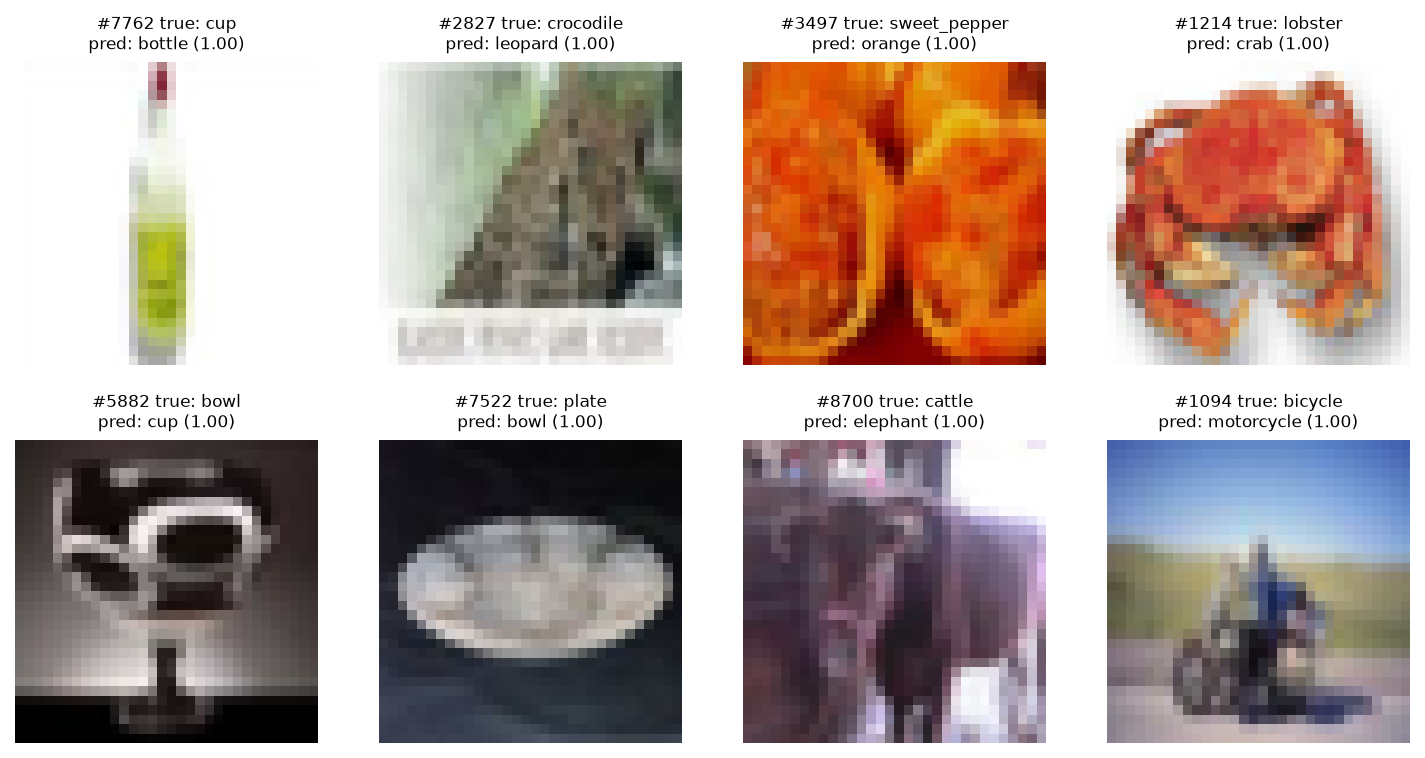

In [9]:
classes = json.loads(Path('reports/image/generated/evidence/swin_t_full/seed_42/split.json').read_text())['classes']
for model in ['resnet18_full','swin_t_full']:
    evaluation = json.loads(Path(f'reports/image/generated/evidence/{model}/seed_42/evaluation_test.json').read_text())
    cm=np.asarray(evaluation['confusion']); errors=cm.copy(); np.fill_diagonal(errors,0)
    print(model)
    for index in np.argsort(errors.ravel())[-5:][::-1]:
        true,pred = np.unravel_index(index,errors.shape)
        print(' ', classes[true], '→', classes[pred], ':', errors[true,pred])
    display(Image(filename=f'reports/image/generated/figures/{model}_errors_test.png'))

## 7. Độ nhạy với ảnh test trùng train

Cùng prediction và checkpoint được giữ nguyên; chỉ loại các ảnh test có RGB bytes trùng một ảnh train. Chỉ số này mô tả độ nhạy của đánh giá, **không phải kết quả train lại sau loại trùng**. Hai nội dung trùng train–validation vẫn có thể ảnh hưởng chọn checkpoint. Near duplicates và chồng lấp với ImageNet chưa được đánh giá.

In [10]:
for original, filtered in zip(groups, sensitivity['groups']):
    delta = 100*(filtered['accuracy']-original['accuracy'])
    print(f"{original['experiment']:20s} gốc {100*original['accuracy']:.3f}% | còn lại {100*filtered['accuracy']:.3f}% | đổi {delta:+.3f} điểm %")

resnet18_scratch     gốc 64.350% | còn lại 64.374% | đổi +0.024 điểm %
resnet18_head        gốc 60.950% | còn lại 60.971% | đổi +0.021 điểm %
resnet18_partial     gốc 73.963% | còn lại 73.997% | đổi +0.034 điểm %
resnet18_full        gốc 78.970% | còn lại 79.009% | đổi +0.039 điểm %
swin_t_scratch       gốc 2.760% | còn lại 2.763% | đổi +0.003 điểm %
swin_t_head          gốc 71.667% | còn lại 71.698% | đổi +0.032 điểm %
swin_t_partial       gốc 78.253% | còn lại 78.288% | đổi +0.035 điểm %
swin_t_full          gốc 86.630% | còn lại 86.677% | đổi +0.047 điểm %


## 8. Nhận xét

Swin-T full có accuracy cao nhất trong setting đã đo; fine-tuning stage cuối hoặc toàn bộ cải thiện so với chỉ học head ở cả hai kiến trúc. Swin-T scratch học kém trong 20 epoch. Lợi thế accuracy của Swin-T full đi kèm chi phí thời gian và bộ nhớ lớn hơn ResNet18 full.

Giới hạn gồm ảnh gốc 32×32, input 96×96, ngân sách cố định, một dataset và ảnh trùng giữa các split. Một nghiên cứu tiếp theo cần chia dữ liệu theo nhóm ảnh trùng trước training, mở rộng kiểm tra near duplicates và đăng ký protocol mới; không điều chỉnh các lượt đã đo theo kết quả test.

Báo cáo sử dụng AI được đính kèm tại `AI_USE_REPORT.md` trong repository. PDF Image có nội dung, nguồn và giới hạn riêng; Tabular/Text và video không được suy ra là hoàn tất từ notebook này.